# Triple Flame

In computational fluid dynamics (CFD) simulation, a triple flame refers to a particular combustion flame configuration that includes three separate flame regions has shown in fig(1) or branches within a combustion chamber. These three flame regions usually signify different combustion modes or stages and possess unique characteristics.The three primary flame regions in a triple configuration are as follows:

- Premixed flame zone:- In this zone the fuel and oxidizer are combined in a specific ratio prior to combustion. This mixture is often a fuel-air mixture that is thoroughly mixed and defined prior to ignition. The result is a stable and rapid combustion process with a high flame temperature and relatively low emissions of pollutants. This zone is typically located at the center of the combustion chamber.

 - Non-premixed Flame Zone:- The zone where the flame moves outward from the premixed region and the fuel and oxidizer mix through diffusion. This type of combustion is slower than in the premixed region and the temperature is lower. The flame in this zone is often more luminous and visibly distinct. The diffusion flame region is typically located beyond the premixed flame

- Lean and Rich premixed flame zone:-In this zone it involves a triple flame that exhibits two distinct branches of premixed flame. The lean premixed flame occurs in regions where there is an excess of oxidizer, while the rich premixed flame occurs in regions with an excess of fuel. These branches result from the interaction of premixed and diffusion flames, creating regions with unique combustion characteristics.

![Schematic-of-the-laminar-triple-flame-The-flame-is-established-by-a-mixture.png](../Figures/tf/tf1.png)                              




source:-[A. Scholtissek, S. Popp and S. Hartl et al. / Combustion and Flame 218 (2020) 205–217](https://www.sciencedirect.com/science/article/abs/pii/S0010218020301929)


This tutorial will guide you on how to simulate a 2D laminar methane-air triple flame. The main goal is to help you understand how to set up boundary conditions and use the helpful pyflut tool effectively. The simulation involves creating a mixture fraction gradient at the inlet boundary, resulting in a flame structure that has both lean and rich premixed flame branches. To accomplish this, It will be using the OpenFOAM framework and the pyflut library. By the end of this tutorial, you will have the necessary knowledge and skills to set up accurate boundary conditions and generate an informative a priori assessment table..

The triple flame is comprised of three unique regions of flame, each exhibiting its own distinct characteristics and combustion reactions. Standard boundary conditions may not fully capture the behavior of these flames. By utilizing [codedFixedValue](https://cfd-training.com/2018/05/07/non-uniform-inlet-profil-with-codedfixedvalue/), you can incorporate custom flame models and complex boundary conditions that account for these unique characteristics.

In order to attain an optimized simulation run, it is imperative to gain insights into the flow and chemical reactions occurring within the simulation case even prior to commencing the actual simulation. Acquiring this knowledge in advance not only facilitates more efficient simulation processes but also enables the maintenance of specific conditions throughout. Python emerges as a prominent tool in these preliminary stages, leveraging the PyFlut kernel in conjunction with Python code to comprehensively understand the behavior of chemical species within the simulation case. Furthermore, this information can be employed to compare simulation results against predefined expectations, ensuring the achievement of desired outcomes. To illustrate this concept, here is a concise example demonstrating how Python can be utilized to orchestrate a gradual increase in species concentration over the simulation domain.

# Pre-processing
### Setting-up TripleFlame for Detailed Chemistry model

####  0 directory

update all the files in 0 directory with new boundary conditions

![image.png](../Figures/tf/tf2.jpg)

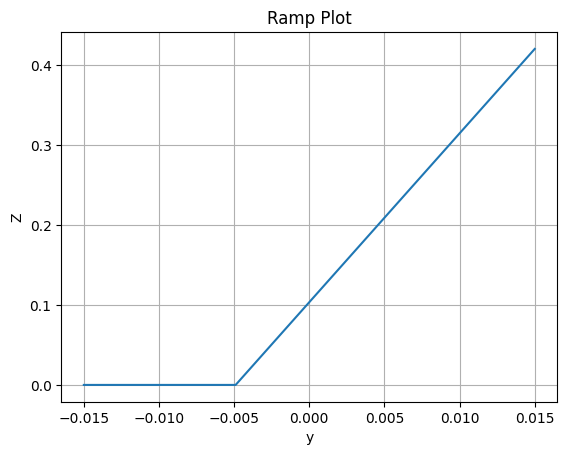

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range for y
y = np.linspace(-0.015, 0.015, 200)

# Initialize Z array
Z = np.zeros_like(y)

# Determine the indices for the constant and varying regions
constant_indices = y < (1/3) * -0.015
varying_indices = ~constant_indices

# Assign constant value to Z for the constant region
Z[constant_indices] = 0.0

# Calculate the varying Z values using linear interpolation
Z_min = 0.0
Z_max = 0.42
varying_region_length = y[varying_indices][-1] - y[varying_indices][0]
Z[varying_indices] = Z_min + (y[varying_indices] - y[varying_indices][0]) / varying_region_length * (Z_max - Z_min)

# Plotting
plt.plot(y, Z)
plt.xlabel('y')
plt.ylabel('Z')
plt.title('Ramp Plot')
plt.grid(True)
plt.show()

#### ControlDict

To adjust the time step in your simulation, you can enable the "adjustTimeStep" option in the "controlDict" file. This will allow the solver to calculate the time step dynamically based on the maximum Courant number (maxCo) that you specified in your simulation setup. Note that this calculation will override any manually set deltaT values.

If you need to modify your simulation settings, you can update the "endTime" parameter to 0.5 seconds and adjust the "writeInterval" to 0.005 seconds. These changes will instruct the solver to write simulation results to the case directory every 0.005 seconds while the simulation is running.

![image.png](../Figures/tf/tf3.png)

#### System directory

- __blockMesh__ :-`blockMesh` is a tool used for creating structured hexahedral(hex) or quadrilateral(quad) meshes for simulation domains. It is particularly useful for relatively simple geometries like pipes, channels, and regular-shaped domains.In this case the vertices and grid of the mesh are changed and To generate the mesh simply type blockMesh in the terminal.

![image.png](../Figures/tf/tf4.png)

- __Pre-procressing slover__ :- After that, the mesh is created in the constant/polyMesh folder. For running the simulation, type the 
solver name form case directory and execute it
`rhoReactingDCFoam`

# Running simulation

To simulate the chemical reacting flows, where there are chemical reactions taking place within the fluid domain. `rhoReactingDCFoam` can be used to model a wide range of combustion and reactions.


Simulations that involve complex geometries, large domains, or high-resolution grids can be computationally demanding and time-consuming. It may not be efficient to run these simulations on a single computer.
To speed up simulations, CFD software such as OpenFOAM can utilize parallel computing. The computational workload is divided among multiple CPU cores or nodes in a cluster. This can greatly decrease simulation times.


To submit the job to the cluster 

`sbatch job.slm`

Slurm batch scripts (usually with a .sh extension) are required when submitting an OpenFOAM simulation job to a cluster using Slurm. The script specifies the job's requirements, resources, and commands to run the simulation. For submitting an OpenFOAM simulation job, here is an example Slurm batch script below.

In [3]:
#!/bin/bash
#SBATCH --job-name  *# job name
#SBATCH --nodes=*               # number of requested nodes
#SBATCH --ntasks-per-node=20 #40 For Athenas, 20 For Pinky nodes    # number of tasks per node
#SBATCH --exclusive
#SBATCH --output output\_%A.out  # where to redirect STDOUT
#SBATCH --error error\_%A.err    # where to redirect SDTERR
#SBATCH --partition a\_medium   # a\_medium for Athena nodes, p\_medium for Pinky nodes
#SBATCH --time 24:00:00         # maximum walltime this job will use, allowed maximum is 48h
###SBATCH --mail-user *   # email address to send notifications to
###SBATCH --mail-type ALL                              # choices: ALL, BEGIN, END, FAIL, REQUEUE

# load an environment, e.g. load some modules, set paths

# here we source the cluster installation of OpenFoam
# source #path of the source file
#dcfoam
# Execute the parallel application
# srun will call mpirun with the above-defined number of cores (nodes \* ntasks-per-node)
# if srun makes problems you can try mpirun -n nodes\*ntasks-per-node rhoFlameletFoam -parallel
#srun rhoReactingDCFoam -parallel

To check the simulation run in parallel. use `squeue` command 

# Post-Processing

Once TurboVNC is installed, which is a remote server where your simulation is running. Then, you would run Paraview on your local machine and use the TurboVNC client to establish a remote desktop connection to the remote server. With this setup, you can use the Paraview graphical interface to visualize and analyze your simulation results which you created a `.foam` file 